# Curse of Dimensionality


[The curse(s) of dimensionality (Altman & Krzywinski, 2018)](https://www.nature.com/articles/s41592-018-0019-x)

[A survey on unsupervised outlier detection in high-dimensional numerical data (Zimek, Schubert, & Kriegel, 2012)](https://onlinelibrary.wiley.com/doi/10.1002/sam.11161)

In [8]:
import numpy as np
from scipy.stats import multivariate_normal
from scipy.special import gamma
from sklearn.metrics import pairwise_distances
import pandas as pd
import matplotlib.pyplot as plt

How does the average distance between data points grow as a function of the dimensionality of the data?

In [33]:
p = 50
n = 10000
samples = multivariate_normal.rvs(np.zeros(p), size=n)

avg_pairwise_dist = {
    "expected": 2 * gamma((p+1)/2) / gamma(p/2),
    "expected (approx.)": np.sqrt(2) * np.sqrt(p),
    "actual": np.mean(pairwise_distances(samples)),
}

print(f"Average pairwise distances for dimension {p=} ({n=})")
for calc_name, calc in avg_pairwise_dist.items():
    print(f"\t{calc_name}: {calc:.2f}")

Average pairwise distances for dimension p=50 (n=10000)
	expected: 9.95
	expected (approx.): 10.00
	actual: 9.96


In [29]:
ps = np.geomspace(2, 100, num=10).astype(np.int64)
n = 10_000

avg_pairwise_dist = {
    "p": ps,
    "expected": [],
    "expected_approx": [],
    "actual": [],
}

for p in ps:
    samples = multivariate_normal.rvs(np.zeros(p), size=n)

    avg_pairwise_dist["expected"].append(2 * gamma((p+1)/2) / gamma(p/2))
    avg_pairwise_dist["expected_approx"].append(np.sqrt(2)*np.sqrt(p))
    avg_pairwise_dist["actual"].append(np.mean(pairwise_distances(samples)))

df = pd.DataFrame(avg_pairwise_dist)
df.head()

,p,expected,expected_approx,actual
0,2,1.772454,2.000000,1.774336
1,3,2.256758,2.449490,2.264159
2,4,2.658681,2.828427,2.668625
3,7,3.610813,3.741657,3.612458
4,11,4.585160,4.690416,4.585461


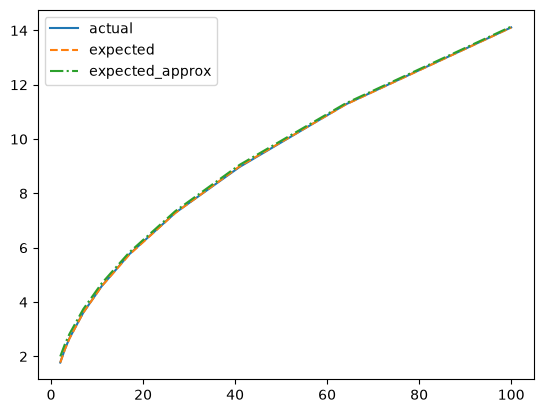

In [30]:
plt.plot(df["p"], df["actual"], label="actual")
plt.plot(df["p"], df["expected"], label="expected", ls="--")
plt.plot(df["p"], df["expected_approx"], label="expected_approx", ls="-.")
plt.legend()
plt.show()